# Análisis de rendimientos y volatilidad de Apple

In [92]:
import numpy as np
import matplotlib.pyplot as plt

#### Entrenamiento

In [93]:
lista_resultados = []
for i in range(1000000):
    resultado = 0
    for i in range(10):
        dado = np.random.randint(1, 7)
        resultado += dado
    if resultado % 6 == 0:
        lista_resultados.append([1])
    else:
        lista_resultados.append([0])

lista_resultados = np.array(lista_resultados)
lista_resultados.mean()

np.float64(0.166567)

#### Exploración de Datos

In [94]:
import pandas as pd
df = pd.read_csv('Datasets/aapl_historical_data_2026_h1.csv')
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2026-01-01,271.13,273.16,270.33,271.76,271.76,48088862
1,2026-01-02,271.56,272.35,270.12,271.01,271.01,52964103
2,2026-01-05,267.08,268.92,265.37,267.40,267.40,63173862
3,2026-01-06,267.77,267.94,265.54,267.45,267.45,55112033
4,2026-01-07,267.95,268.14,265.63,267.63,267.63,67043445


In [95]:
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,129.000000,129.000000,129.000000,129.000000,129.000000,1.290000e+02
mean,273.857752,275.399845,272.113023,273.789225,273.789225,5.966355e+07
std,20.204258,20.277666,20.036950,20.061188,20.061188,1.431972e+07
min,246.640000,248.020000,245.090000,246.610000,246.610000,3.506766e+07
25%,258.870000,259.570000,256.720000,258.610000,258.610000,4.808886e+07
50%,267.950000,269.110000,266.340000,268.080000,268.080000,5.824098e+07
75%,290.660000,293.030000,288.590000,291.410000,291.410000,7.108139e+07
max,315.670000,318.000000,313.090000,315.200000,315.200000,8.409440e+07


In [96]:
print(df['Date'].min(), df['Date'].max())

2026-01-01 2026-06-30


In [97]:
print(df[df['Volume'] == df['Volume'].max()]['Date'])
print(df[df['Volume'] == df['Volume'].min()]['Date'])

47    2026-03-09
Name: Date, dtype: object
119    2026-06-17
Name: Date, dtype: object


#### Cálculo de Rendimientos

In [98]:
df['R_log'] = np.log(df['Close'] / df['Close'].shift(1))
df.head()
df = df.dropna()

#### Cálculo de Media y Volatilidad

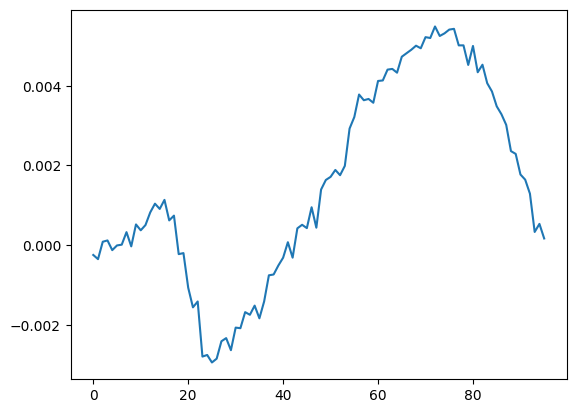

In [99]:
medias_m = []
for i in range(96):
    media = df.loc[i:32+i, 'R_log'].mean()
    medias_m.append(media)

import matplotlib.pyplot as plt
plt.plot(medias_m)
plt.show()

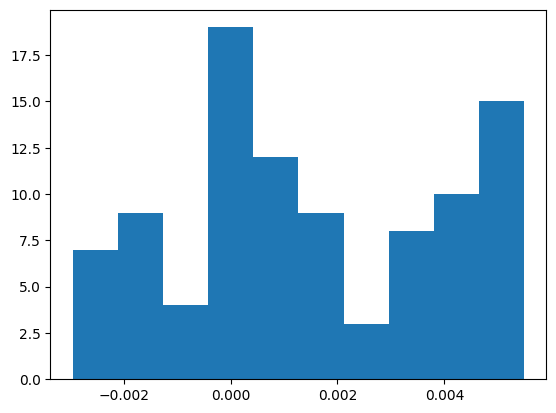

In [100]:
plt.hist(medias_m)
plt.show()

In [121]:
s = []
for i in range(len(medias_m)):
    s.append(np.sqrt((1/(len(medias_m)-1))*sum((df['R_log']-medias_m[i])**2)))

In [ ]:
x_test = df['R_log'].mean()
s_mue = np.sqrt((1/127)*sum((df['R_log']-x_test)**2))
print(x_test, s_mue)

0.0004902520608712074 0.009958376759008743


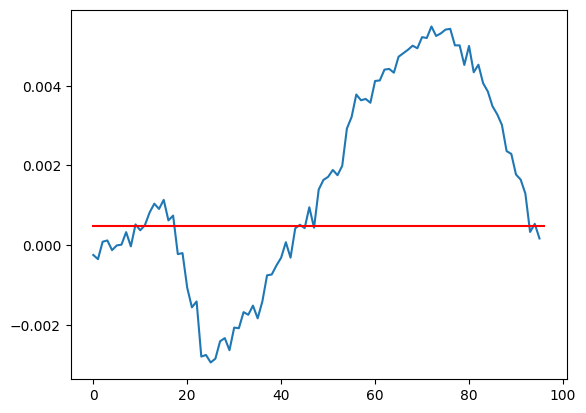

In [107]:
plt.plot(medias_m)
plt.plot([0,96], [x_test,x_test], color='red')
plt.show()

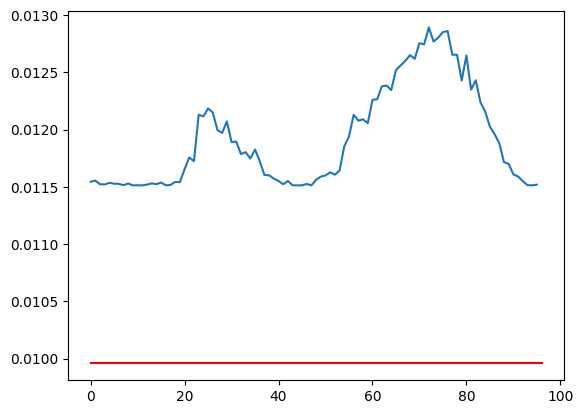

In [119]:
plt.plot(s)
plt.plot([0,96], [s_mue,s_mue], color='red')
plt.show()